In [1]:
FIRST_NAME = "Indhuja"
LAST_NAME = "Gudluru"
STUDENT_ID = "801366046"

In [2]:
# Extra imports for this lab that are beyond the scope of discussion
import os
import gc
import traceback
import warnings
from pdb import set_trace

# Set this to True if you DO NOT want to run the
# garbage_collect() functions throughout the notebook
turn_off_garbage_collect = False

def garbage_collect(vars_):
    if not turn_off_garbage_collect:
        for v in vars_:
            if v in globals():
                del globals()[v]
        collected = gc.collect()


class TodoCheckFailed(Exception):
    pass

def todo_check(asserts):
    failed_err = "You passed {}/{} and FAILED the following code checks:\n{}"
    failed = ""
    n_failed = 0
    for check, (condi, err) in enumerate(asserts):
        exc_failed = False
        if isinstance(condi, str):
            try:
                passed = eval(condi)
            except Exception:
                exc_failed = True
                n_failed += 1
                failed += f"\nCheck [{check+1}]: Failed to execute check [{check+1}] due to the following error...\n{traceback.format_exc()}"
        elif isinstance(condi, bool):
            passed = condi
        else:
            raise ValueError("asserts must be a list of strings or bools")

        if not exc_failed and not passed:
            n_failed += 1
            failed += f"\nCheck [{check+1}]: Failed\n\tTip: {err}\n"

    if len(failed) != 0:
        passed = len(asserts) - n_failed
        err = failed_err.format(passed, len(asserts), failed)
        raise TodoCheckFailed(err.format(failed))
    print("Your code PASSED the code check!")

In [3]:
!pip install numpy
!pip install pandas
!pip install matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# This is a python magic command.
# This command allows the output of matplotlib to be displayed inline, i.e. under the cell.
%matplotlib inline


[notice] A new release of pip is available: 23.2.1 -> 23.3.2
[notice] To update, run: C:\Users\indhu\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.2.1 -> 23.3.2
[notice] To update, run: C:\Users\indhu\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.2.1 -> 23.3.2
[notice] To update, run: C:\Users\indhu\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [4]:
%pfile garments_worker_productivity.csv

Object `garments_worker_productivity.csv` not found.


date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1/1/2015,Quarter1,sweing,Thursday,8,0.8,26.16,1108,7080,98,0,0,0,59,0.940725424
1/1/2015,Quarter1,finishing ,Thursday,1,0.75,3.94,,960,0,0,0,0,8,0.8865
1/1/2015,Quarter1,sweing,Thursday,11,0.8,11.41,968,3660,50,0,0,0,30.5,0.800570492
1/1/2015,Quarter1,sweing,Thursday,12,0.8,11.41,968,3660,50,0,0,0,30.5,0.800570492
1/1/2015,Quarter1,sweing,Thursday,6,0.8,25.9,1170,1920,50,0,0,0,56,0.800381944
1/1/2015,Quarter1,sweing,Thursday,7,0.8,25.9,984,6720,38,0,0,0,56,0.800125
1/1/2015,Quarter1,finishing ,Thursday,2,0.75,3.94,,960,0,0,0,0,8,0.755166667
1/1/2015,Quarter1,sweing,Thursday,3,0.75,28.08,795,6900,45,0,0,0,57.5,0.753683478
1/1/2015,Quarter1,sweing,Thursday,2,0.75,19.87,733,6000,34,0,0,0,55,0.753097531
1/1/2015,Quarter1,sweing,Thursday,1,0.75,28.08,681,6900,45,0,0,0,57.5,0.750427826
1/1/2015,Quarter1,sweing,Thursday,9,0.7,28.08,872,6900

In [5]:
!type garments_worker_productivity.csv

date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1/1/2015,Quarter1,sweing,Thursday,8,0.8,26.16,1108,7080,98,0,0,0,59,0.940725424
1/1/2015,Quarter1,finishing ,Thursday,1,0.75,3.94,,960,0,0,0,0,8,0.8865
1/1/2015,Quarter1,sweing,Thursday,11,0.8,11.41,968,3660,50,0,0,0,30.5,0.800570492
1/1/2015,Quarter1,sweing,Thursday,12,0.8,11.41,968,3660,50,0,0,0,30.5,0.800570492
1/1/2015,Quarter1,sweing,Thursday,6,0.8,25.9,1170,1920,50,0,0,0,56,0.800381944
1/1/2015,Quarter1,sweing,Thursday,7,0.8,25.9,984,6720,38,0,0,0,56,0.800125
1/1/2015,Quarter1,finishing ,Thursday,2,0.75,3.94,,960,0,0,0,0,8,0.755166667
1/1/2015,Quarter1,sweing,Thursday,3,0.75,28.08,795,6900,45,0,0,0,57.5,0.753683478
1/1/2015,Quarter1,sweing,Thursday,2,0.75,19.87,733,6000,34,0,0,0,55,0.753097531
1/1/2015,Quarter1,sweing,Thursday,1,0.75,28.08,681,6900,45,0,0,0,57.5,0.750427826
1/1/2015,Quarter1,sweing,Thursday,9,0.7,28.08,872,6900

In [6]:
!powershell Get-Content -Head 30 garments_worker_productivity.csv      # For Windows

date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1/1/2015,Quarter1,sweing,Thursday,8,0.8,26.16,1108,7080,98,0,0,0,59,0.940725424
1/1/2015,Quarter1,finishing ,Thursday,1,0.75,3.94,,960,0,0,0,0,8,0.8865
1/1/2015,Quarter1,sweing,Thursday,11,0.8,11.41,968,3660,50,0,0,0,30.5,0.800570492
1/1/2015,Quarter1,sweing,Thursday,12,0.8,11.41,968,3660,50,0,0,0,30.5,0.800570492
1/1/2015,Quarter1,sweing,Thursday,6,0.8,25.9,1170,1920,50,0,0,0,56,0.800381944
1/1/2015,Quarter1,sweing,Thursday,7,0.8,25.9,984,6720,38,0,0,0,56,0.800125
1/1/2015,Quarter1,finishing ,Thursday,2,0.75,3.94,,960,0,0,0,0,8,0.755166667
1/1/2015,Quarter1,sweing,Thursday,3,0.75,28.08,795,6900,45,0,0,0,57.5,0.753683478
1/1/2015,Quarter1,sweing,Thursday,2,0.75,19.87,733,6000,34,0,0,0,55,0.753097531
1/1/2015,Quarter1,sweing,Thursday,1,0.75,28.08,681,6900,45,0,0,0,57.5,0.750427826
1/1/2015,Quarter1,sweing,Thursday,9,0.7,28.08,872,6900

In [7]:
!powershell Get-Content -Tail 30 garments_worker_productivity.csv      # For Windows

3/10/2015,Quarter2,sweing,Tuesday,2,0.7,16.1,957,5400,40,0,0,1,45,0.700051852
3/10/2015,Quarter2,sweing,Tuesday,5,0.65,26.82,1001,7080,26,0,0,1,59,0.650044068
3/10/2015,Quarter2,sweing,Tuesday,7,0.6,30.48,1017,6840,25,0,0,1,57,0.630402924
3/10/2015,Quarter2,finishing,Tuesday,8,0.65,3.9,,960,0,0,0,0,8,0.560625
3/10/2015,Quarter2,finishing,Tuesday,7,0.5,3.9,,960,0,0,0,0,8,0.560625
3/10/2015,Quarter2,finishing,Tuesday,10,0.7,2.9,,960,0,0,0,0,8,0.39875
3/11/2015,Quarter2,finishing,Wednesday,12,0.8,4.6,,2160,0,0,0,0,9,0.922839506
3/11/2015,Quarter2,finishing,Wednesday,11,0.8,2.9,,2400,0,0,0,0,10,0.874027778
3/11/2015,Quarter2,finishing,Wednesday,2,0.75,3.9,,1920,0,0,0,0,8,0.819270833
3/11/2015,Quarter2,finishing,Wednesday,4,0.75,3.94,,1920,0,0,0,0,8,0.813309028
3/11/2015,Quarter2,finishing,Wednesday,1,0.75,3.94,,1920,0,0,0,0,8,0.812625
3/11/2015,Quarter2,sweing,Wednesday,12,0.8,15.26,470,4080,63,0,0,0,34,0.800401961
3/11/2015,Quarter2,sweing,Wednesday,3,0.8,30.1,735,6960,63,0,0,1,58,0.80007

In [8]:
# This line checks to make sure the garments_worker_productivity.csv is in the
# same directory as this notebook, if not it will throw a warning.
if not os.path.exists("garments_worker_productivity.csv"):
    warning.warn(f"The garments_worker_productivity.csv is not detected in your local path! " \
                f"You need to move the 'garments_worker_productivity.csv' file to the same " \
                f"location/directory as this notebook which is {os.getcwd()}")

In [9]:
# Instead of having the error thrown directly, we will catch it and
# print it out using the traceback library.
try:
    data = np.loadtxt("garments_worker_productivity.csv")
except ValueError:
    traceback.print_exc()

ValueError: could not convert string to float: 'date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity'

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "C:\Users\indhu\AppData\Local\Temp\ipykernel_27948\3942526630.py", line 4, in <module>
    data = np.loadtxt("garments_worker_productivity.csv")
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\npyio.py", line 1373, in loadtxt
    arr = _read(fname, dtype=dtype, comment=comment, delimiter=delimiter,
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\npyio.py", line 1016, in _read
    arr = _load_from_filelike(
          ^^^^^^^^^^^^^^^^^^^^
ValueError: could not co

In [10]:
# Python dictionaries that map the expected strings contained withing the data to our specified output
quarterdic = {b'Quarter1': 1, b'Quarter2':2, b'Quarter3':3, b'Quarter4':4, b'Quarter5':5}
daydic = {b'Sunday': 1, b'Monday':2, b'Tuesday':3, b'Wednesday':4, b'Thursday':5, b'Friday':6, b'Saturday':7 }
deptdic = {b'sweing': 1, b'finishing ':2, b'finishing':3}
dates_list = pd.read_csv('garments_worker_productivity.csv')["date"].unique()
datedic = {bytes(dates_list[i], 'utf-8'):i+1 for i in range(len(dates_list))}

def quarter_conv(s):
    """ Simple python function that returns the value from the quarterdic given a key. """
    return quarterdic[s]

def day_conv(s):
    """ Simple python function that returns the value from the daydic given a key. """
    return daydic[s]

def dept_conv(s):
    """ Simple python function that returns the value from the deptdic given a key. """
    return deptdic[s]

def date_conv(s):
    """ Simple python function that returns the value from the datedic given a key. """
    return datedic[s]

try:
    dat = np.loadtxt("garments_worker_productivity.csv", delimiter=',', skiprows=1,
                     converters={0:date_conv, 1:quarter_conv, 2:dept_conv, 3:day_conv}, encoding="utf-8-sig")
    dat
except:
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\indhu\AppData\Local\Temp\ipykernel_27948\2677093468.py", line 22, in date_conv
    return datedic[s]
           ~~~~~~~^^^
KeyError: '1/1/2015'

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "C:\Users\indhu\AppData\Local\Temp\ipykernel_27948\2677093468.py", line 25, in <module>
    dat = np.loadtxt("garments_worker_productivity.csv", delimiter=',', skiprows=1,
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\npyio.py", line 1373, in loadtxt
    arr = _read(fname, dtype=dtype, comment=comment, delimiter=delimiter,
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\npyio.py", line 1016, in _read
    arr = _load_from_filelike(
          

In [11]:
dat = np.genfromtxt("garments_worker_productivity.csv", delimiter=',', skip_header=1,
                   converters={0: date_conv, 1: quarter_conv, 2: dept_conv, 3: day_conv}, dtype=None)

dat # Adding a variable to the last line of a cell will automatically print its output below

array([( 1, 1, 1, 5,  8, 0.8 , 26.16, 1108, 7080, 98, 0., 0, 0, 59. , 0.94072542),
       ( 1, 1, 2, 5,  1, 0.75,  3.94,   -1,  960,  0, 0., 0, 0,  8. , 0.8865    ),
       ( 1, 1, 1, 5, 11, 0.8 , 11.41,  968, 3660, 50, 0., 0, 0, 30.5, 0.80057049),
       ...,
       (59, 2, 3, 4,  7, 0.65,  3.9 ,   -1,  960,  0, 0., 0, 0,  8. , 0.625625  ),
       (59, 2, 3, 4,  9, 0.75,  2.9 ,   -1, 1800,  0, 0., 0, 0, 15. , 0.50588889),
       (59, 2, 3, 4,  6, 0.7 ,  2.9 ,   -1,  720,  0, 0., 0, 0,  6. , 0.39472222)],
      dtype=[('f0', '<i4'), ('f1', '<i4'), ('f2', '<i4'), ('f3', '<i4'), ('f4', '<i4'), ('f5', '<f8'), ('f6', '<f8'), ('f7', '<i4'), ('f8', '<i4'), ('f9', '<i4'), ('f10', '<f8'), ('f11', '<i4'), ('f12', '<i4'), ('f13', '<f8'), ('f14', '<f8')])

In [12]:
# Or using lambda function

dat = np.genfromtxt("garments_worker_productivity.csv", delimiter=',', skip_header=1,
                   converters={0: lambda x: datedic[x], 1: lambda x: quarterdic[x],
                               2: lambda x: deptdic[x], 3: lambda x: daydic[x]}, dtype=None)
dat

array([( 1, 1, 1, 5,  8, 0.8 , 26.16, 1108, 7080, 98, 0., 0, 0, 59. , 0.94072542),
       ( 1, 1, 2, 5,  1, 0.75,  3.94,   -1,  960,  0, 0., 0, 0,  8. , 0.8865    ),
       ( 1, 1, 1, 5, 11, 0.8 , 11.41,  968, 3660, 50, 0., 0, 0, 30.5, 0.80057049),
       ...,
       (59, 2, 3, 4,  7, 0.65,  3.9 ,   -1,  960,  0, 0., 0, 0,  8. , 0.625625  ),
       (59, 2, 3, 4,  9, 0.75,  2.9 ,   -1, 1800,  0, 0., 0, 0, 15. , 0.50588889),
       (59, 2, 3, 4,  6, 0.7 ,  2.9 ,   -1,  720,  0, 0., 0, 0,  6. , 0.39472222)],
      dtype=[('f0', '<i4'), ('f1', '<i4'), ('f2', '<i4'), ('f3', '<i4'), ('f4', '<i4'), ('f5', '<f8'), ('f6', '<f8'), ('f7', '<i4'), ('f8', '<i4'), ('f9', '<i4'), ('f10', '<f8'), ('f11', '<i4'), ('f12', '<i4'), ('f13', '<f8'), ('f14', '<f8')])

In [13]:
dat.shape

(1197,)

In [14]:
np.any?

Signature:       np.any(a, axis=None, out=None, keepdims=<no value>, *, where=<no value>)
Call signature:  np.any(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function any at 0x000002169E130CC0>
File:            c:\users\indhu\appdata\local\programs\python\python312\lib\site-packages\numpy\core\fromnumeric.py
Docstring:      
Test whether any array element along a given axis evaluates to True.

Returns single boolean if `axis` is ``None``

Parameters
----------
a : array_like
    Input array or object that can be converted to an array.
axis : None or int or tuple of ints, optional
    Axis or axes along which a logical OR reduction is performed.
    The default (``axis=None``) is to perform a logical OR over all
    the dimensions of the input array. `axis` may be negative, in
    which case it counts from the last to the first axis.

    .. versionadded:: 1.7.0

    If this is a tuple of ints, a reduction is performed on multiple
    axes, instead of a 

In [15]:
# This will delete the variables defined in the above section to
# prevent conflicts in future sections.
garbage_collect(['data', 'quarterdic', 'daydic', 'deptdic', 'dates_list', 'datedic', 'datedic_bytes'])


In [16]:
  # Example TODO
  df = pd.read_csv("garments_worker_productivity.csv")
  df

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,3/11/2015,Quarter2,finishing,Wednesday,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,3/11/2015,Quarter2,finishing,Wednesday,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,3/11/2015,Quarter2,finishing,Wednesday,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889


In [17]:
#TODO 2.1
# Accessing the first 10 rows
first_ten_rows = df.head(10)
first_ten_rows

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
5,1/1/2015,Quarter1,sweing,Thursday,7,0.80,25.90,984.0,6720,38,0.0,0,0,56.0,0.800125
6,1/1/2015,Quarter1,finishing,Thursday,2,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.755167
7,1/1/2015,Quarter1,sweing,Thursday,3,0.75,28.08,795.0,6900,45,0.0,0,0,57.5,0.753683
8,1/1/2015,Quarter1,sweing,Thursday,2,0.75,19.87,733.0,6000,34,0.0,0,0,55.0,0.753098
9,1/1/2015,Quarter1,sweing,Thursday,1,0.75,28.08,681.0,6900,45,0.0,0,0,57.5,0.750428


In [18]:
todo_check([
    ("np.all(first_ten_rows.iloc[[0, 9], :].values == np.array([['1/1/2015','Quarter1','sweing','Thursday',8,0.8,26.16,1108,7080,98,0,0,0,59,0.940725424], ['1/1/2015','Quarter1','sweing','Thursday',1,0.75,28.08,681,6900,45,0,0,0,57.5,0.750427826]], dtype=object))",
     "first_ten_rows has incorrect values.")
])

Your code PASSED the code check!


In [19]:
# TODO 2.2
# Accessing the column names
df_columns = df.columns.values
df_columns

array(['date', 'quarter', 'department', 'day', 'team',
       'targeted_productivity', 'smv', 'wip', 'over_time', 'incentive',
       'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers',
       'actual_productivity'], dtype=object)

In [20]:
todo_check([
    ('isinstance(df_columns, (np.ndarray, list))', f"df_columns is not type np.ndarray or list, rather it is type {type(df_columns)}."),
    ('len(df_columns) == 15', "df_columns has incorrect number of values."),
    ("np.all(df_columns == np.array(['date', 'quarter', 'department', 'day', 'team', 'targeted_productivity', 'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers', 'actual_productivity']))", "df_column names were incorrect!")
])

Your code PASSED the code check!


In [21]:
# TODO 2.3
# Accessing the shape of the DataFrame
df_shape = df.shape
df_shape

(1197, 15)

In [22]:
todo_check([
    ("len(df_shape) == 2", "df_shape has incorrect number of values."),
    ("df_shape == (1197, 15)", "df_shape values was incorrect.")
])

Your code PASSED the code check!


In [23]:
# TODO 2.4
# Accessing the size of the DataFrame
df_size = df.size
df_size

17955

In [24]:
todo_check([
    ("df_size == 17955", "df_size value was incorrect.")
])

Your code PASSED the code check!


In [25]:
# This will delete the variables defined in the above section to
# prevent conflicts in future sections
garbage_collect(['first_ten_rows', 'df_columns', 'df_shape', 'df_size'])

In [26]:
# TODO 3-1.1
# Convert df to a boolean DataFrame where True indicates a missing value
null_df = df.isnull()
null_df

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
1193,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
1194,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False
1195,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False


In [27]:
# TODO 3-1.2
# Check if there are any missing values in the DataFrame
any_nulls = np.any(null_df)
any_nulls

True

In [28]:
todo_check([
    ("any_nulls == True", "any_nulls value is incorrect.")
])

Your code PASSED the code check!


In [29]:
# TODO 3-2.1
# Select the 'actual_productivity' column using the column's name
actual_productivity = df['actual_productivity']
actual_productivity

0       0.940725
1       0.886500
2       0.800570
3       0.800570
4       0.800382
          ...   
1192    0.628333
1193    0.625625
1194    0.625625
1195    0.505889
1196    0.394722
Name: actual_productivity, Length: 1197, dtype: float64

In [30]:
todo_check([
    ("actual_productivity.shape == (1197,) or actual_productivity.shape == (1197,1) ", "actual_productivity has the wrong shape."),
    ("np.all(actual_productivity.iloc[[1194, 1195, 1196]].values.flatten() == np.array([ 0.625625, 0.505888889, 0.394722222]))", "actual_productivity values are incorrect.")
])

Your code PASSED the code check!


In [31]:
# TODO 3-3.1
# Use the describe method to compute a summary of statistics
df_describe = df.describe()
df_describe

,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
count,1197.000000,1197.000000,1197.000000,691.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,6.426901,0.729632,15.062172,1190.465991,4567.460317,38.210526,0.730159,0.369256,0.150376,34.609858,0.735091
std,3.463963,0.097891,10.943219,1837.455001,3348.823563,160.182643,12.709757,3.268987,0.427848,22.197687,0.174488
min,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.233705
25%,3.000000,0.700000,3.940000,774.500000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.650307
50%,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.773333
75%,9.000000,0.800000,24.260000,1252.500000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000,0.850253
max,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,89.000000,1.120437


In [32]:
todo_check([
    ("df_describe.shape == (8,11)", "df_describe has the wrong shape."),
    ("np.all(np.isclose(np.diag(df_describe), np.array([1197., 0.7296324143692557, 10.943219199514333, 7., 1440., 0., 0., 45.])))",
     "df_describe values are incorrect.")
])

Your code PASSED the code check!


In [33]:
# This will delete the variables defined in the above section to
# prevent conflicts in future sections.
garbage_collect(['actual_productivity', 'df_describe', 'null_df', 'any_nulls'])

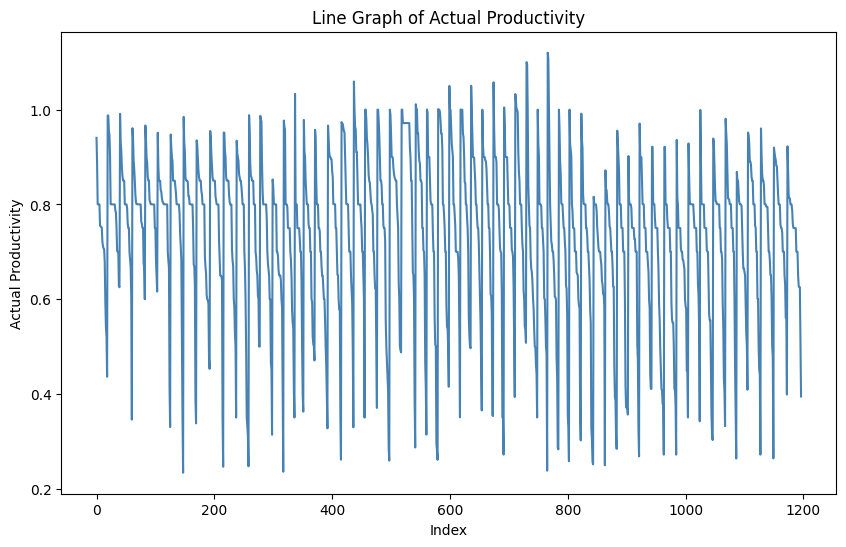

In [34]:
# TODO 4.1
plt.figure(figsize=(10,6))
plt.plot(df['actual_productivity'], color='steelblue', linewidth=1.5)  # blue color, thinner line
plt.title('Line Graph of Actual Productivity')
plt.xlabel('Index')  
plt.ylabel('Actual Productivity')
plt.show()

(array([ 34.  59.  38.  74. 137. 250. 340. 151. 104.  10.]),
array([0.23370548 0.32237868 0.41105188 0.49972508 0.58839829 0.67707149
 0.76574469 0.85441789 0.9430911  1.0317643  1.1204375 ]),


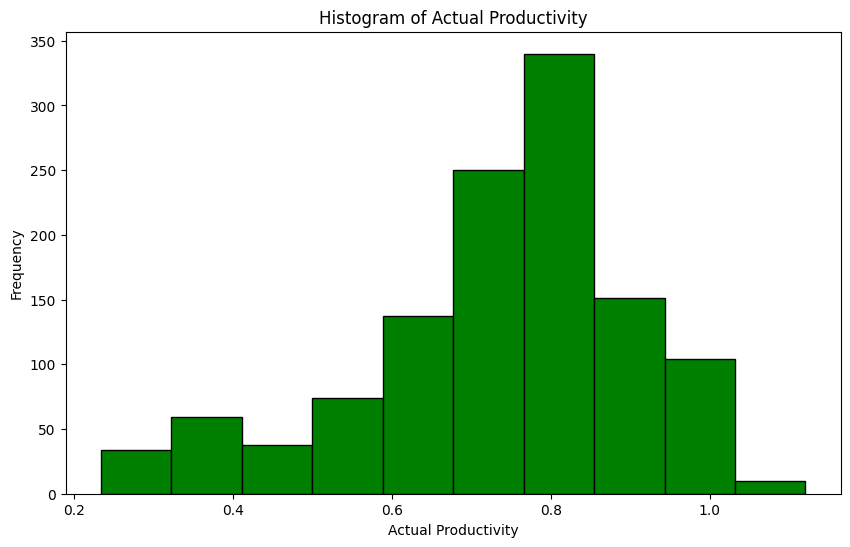

In [35]:
# TODO 4.2
# Calculate the histogram data
plt.figure(figsize=(10,6))
# Unpack all three returned values, ignoring 'patches' with '_'
bin_counts, bin_edges, _ = plt.hist(df['actual_productivity'], bins=10, color='green', edgecolor='black', alpha=1)

# Print the histogram data
print(f"(array({bin_counts}),")
print(f"array({bin_edges}),")

# Add plot titles and labels
plt.title('Histogram of Actual Productivity')
plt.xlabel('Actual Productivity')
plt.ylabel('Frequency')

# Show the plot
plt.show()

In [36]:
# Store target feature in T
T = df.loc[:, 'actual_productivity'].copy()
T

0       0.940725
1       0.886500
2       0.800570
3       0.800570
4       0.800382
          ...   
1192    0.628333
1193    0.625625
1194    0.625625
1195    0.505889
1196    0.394722
Name: actual_productivity, Length: 1197, dtype: float64

In [37]:
# Store remaining features in X
X = df.iloc[:, :-1].copy()
X

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0
1193,3/11/2015,Quarter2,finishing,Wednesday,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0
1194,3/11/2015,Quarter2,finishing,Wednesday,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0
1195,3/11/2015,Quarter2,finishing,Wednesday,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0


In [38]:
# TODO 5.1

# Define your dictionaries
quarterdic = {'Quarter1': 1, 'Quarter2': 2, 'Quarter3': 3, 'Quarter4': 4, 'Quarter5': 5}
daydic = {'Sunday': 1, 'Monday': 2, 'Tuesday': 3, 'Wednesday': 4, 'Thursday': 5, 'Friday': 6, 'Saturday': 7}
departmentdic = {'sweing': 1, 'finishing ': 2, 'finishing': 3}
dates_list = df["date"].unique()
datedic = {dates_list[i]:i+1 for i in range(len(dates_list))}
X['date'] = X['date'].apply(lambda x: datedic[x])
X['quarter'] = X['quarter'].apply(lambda x: quarterdic[x])
X['department'] = X['department'].apply(lambda x: departmentdic[x])
X['day'] = X['day'].apply(lambda x: daydic[x])
X
                                                     

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers
0,1,1,1,5,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0
1,1,1,2,5,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0
2,1,1,1,5,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5
3,1,1,1,5,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5
4,1,1,1,5,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59,2,3,4,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0
1193,59,2,3,4,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0
1194,59,2,3,4,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0
1195,59,2,3,4,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0


In [39]:
todo_check([
    ("np.all(X['quarter'].iloc[[0,1,200,513,516]].values == np.array([ 1,1,2,5,5]))", "X 'quarter' column has incorrect values"),
    ("np.all(X['day'].iloc[[0,1,200,513,516]].values == np.array([5, 5, 2, 5, 5]))", "X 'day' column has incorrect values"),
    ("np.all(X['department'].iloc[[0,1,200,513,516]].values == np.array([1, 2, 1, 2, 2]))", "X 'department' column has incorrect values"),
    ("np.all(X['date'].iloc[[0,1,200,513,516]].values == np.array([1, 1, 10, 25, 25]))", "X 'date' column has incorrect values"),
])

Your code PASSED the code check!


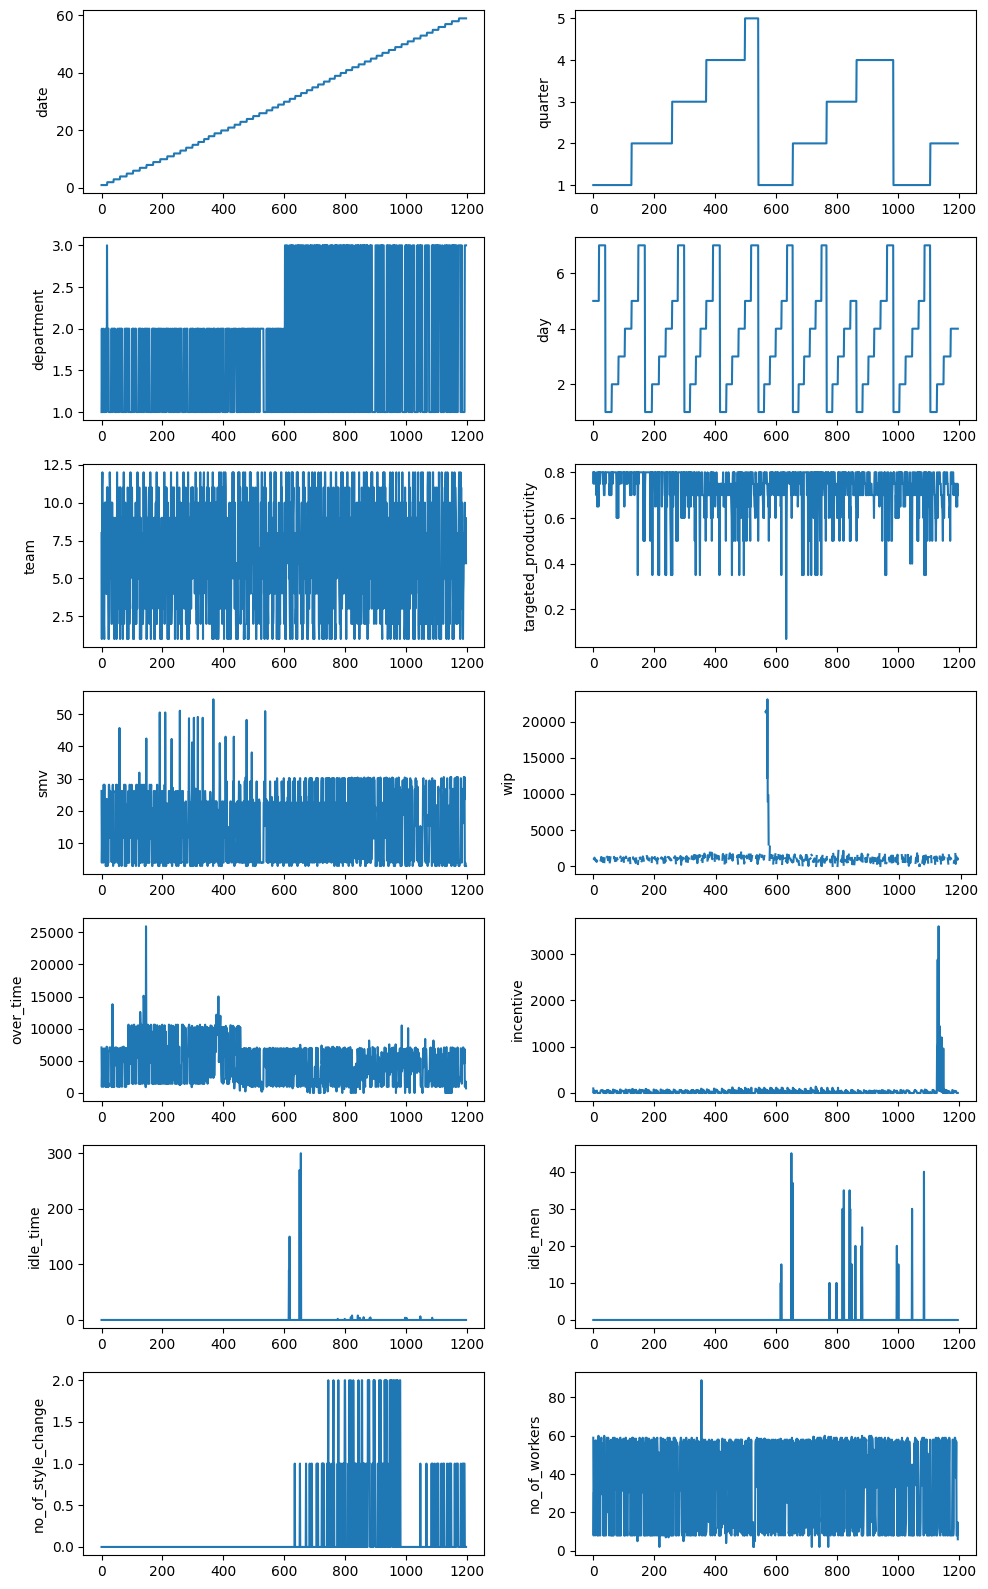

In [40]:
fig = plt.figure(figsize=(10,16))
plt.clf() # Clear previous plt figure
for i in range(14):
    plt.subplot(7, 2, i+1) # Selects which subplot to plot to
    plt.plot(X.iloc[:, i]) # Plots a given column
    plt.ylabel(X.columns.values[i]) # Sets Y label
fig.tight_layout()

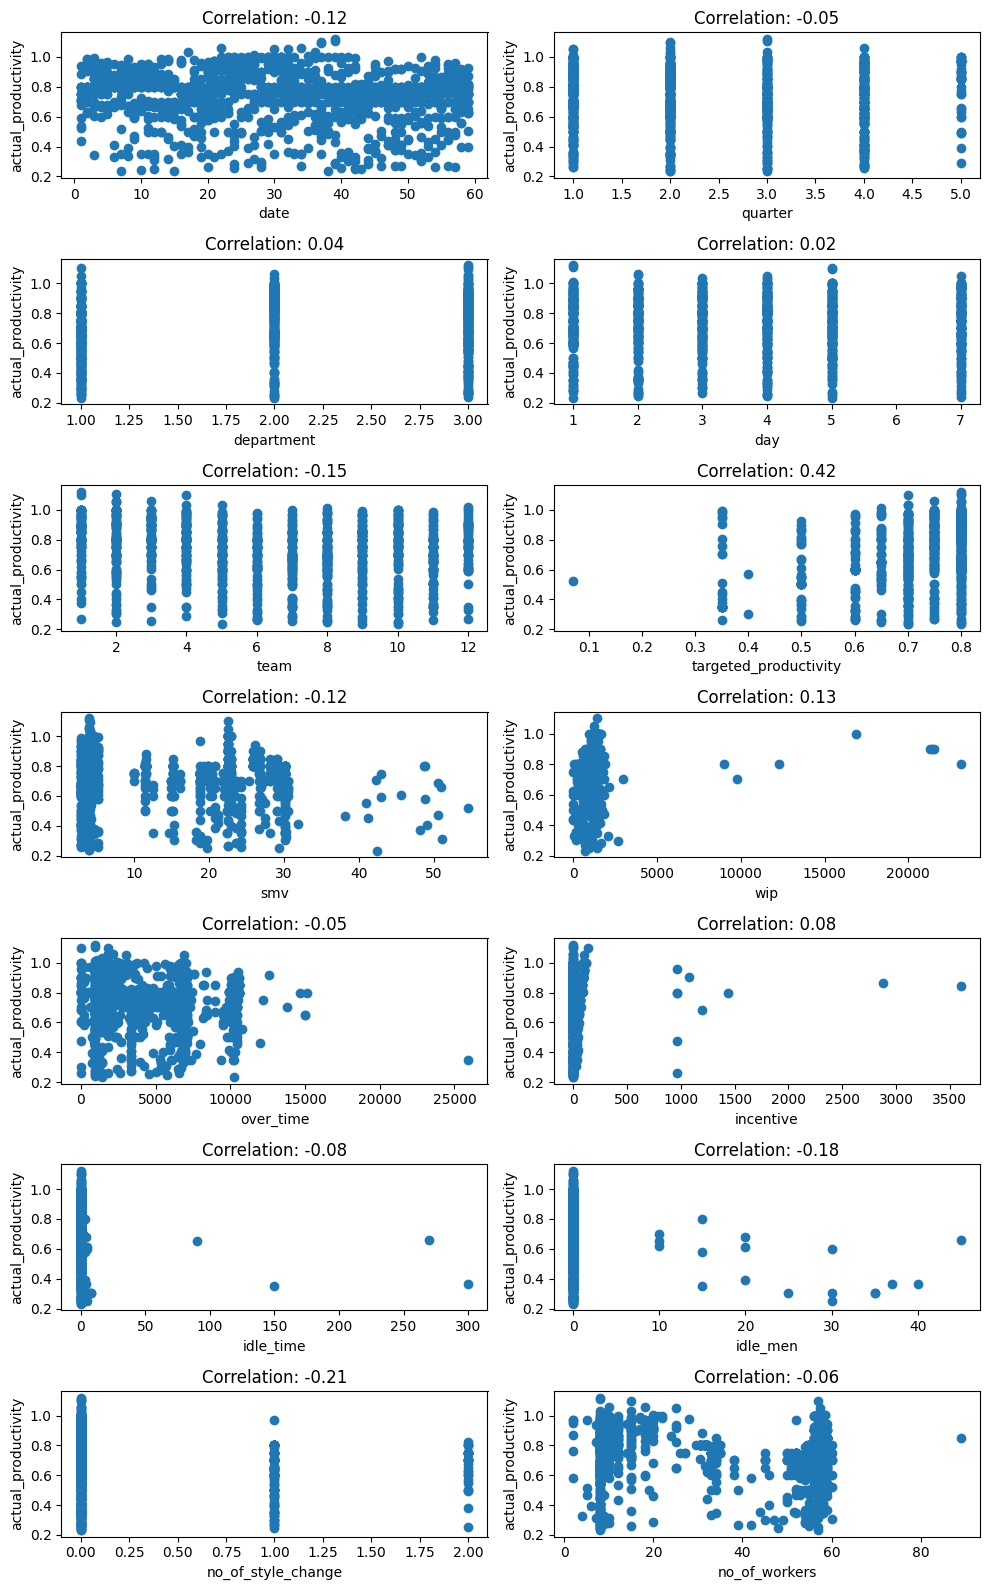

In [41]:
# TODO 6.1
fig = plt.figure(figsize=(10, 16))
plt.clf()  # Clear the previous plt figure

for i in range(len(X.columns)):
    plt.subplot(7, 2, i + 1)  # Selects which subplot to plot to
    plt.scatter(X.iloc[:, i], df['actual_productivity'])  # Scatter plot of feature vs target
    correlation = X.iloc[:, i].corr(df['actual_productivity'])  # Calculate the correlation coefficient
    plt.xlabel(X.columns.values[i])  # Sets X label
    plt.ylabel('actual_productivity')  # Sets Y label
    plt.title(f'Correlation: {correlation:.2f}')  # Display correlation coefficient in the title


fig.tight_layout()
plt.show()

In [42]:
D = pd.concat([X, T], axis=1)
D

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1,1,1,5,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1,1,2,5,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1,1,1,5,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1,1,1,5,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1,1,1,5,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59,2,3,4,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,59,2,3,4,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,59,2,3,4,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,59,2,3,4,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889


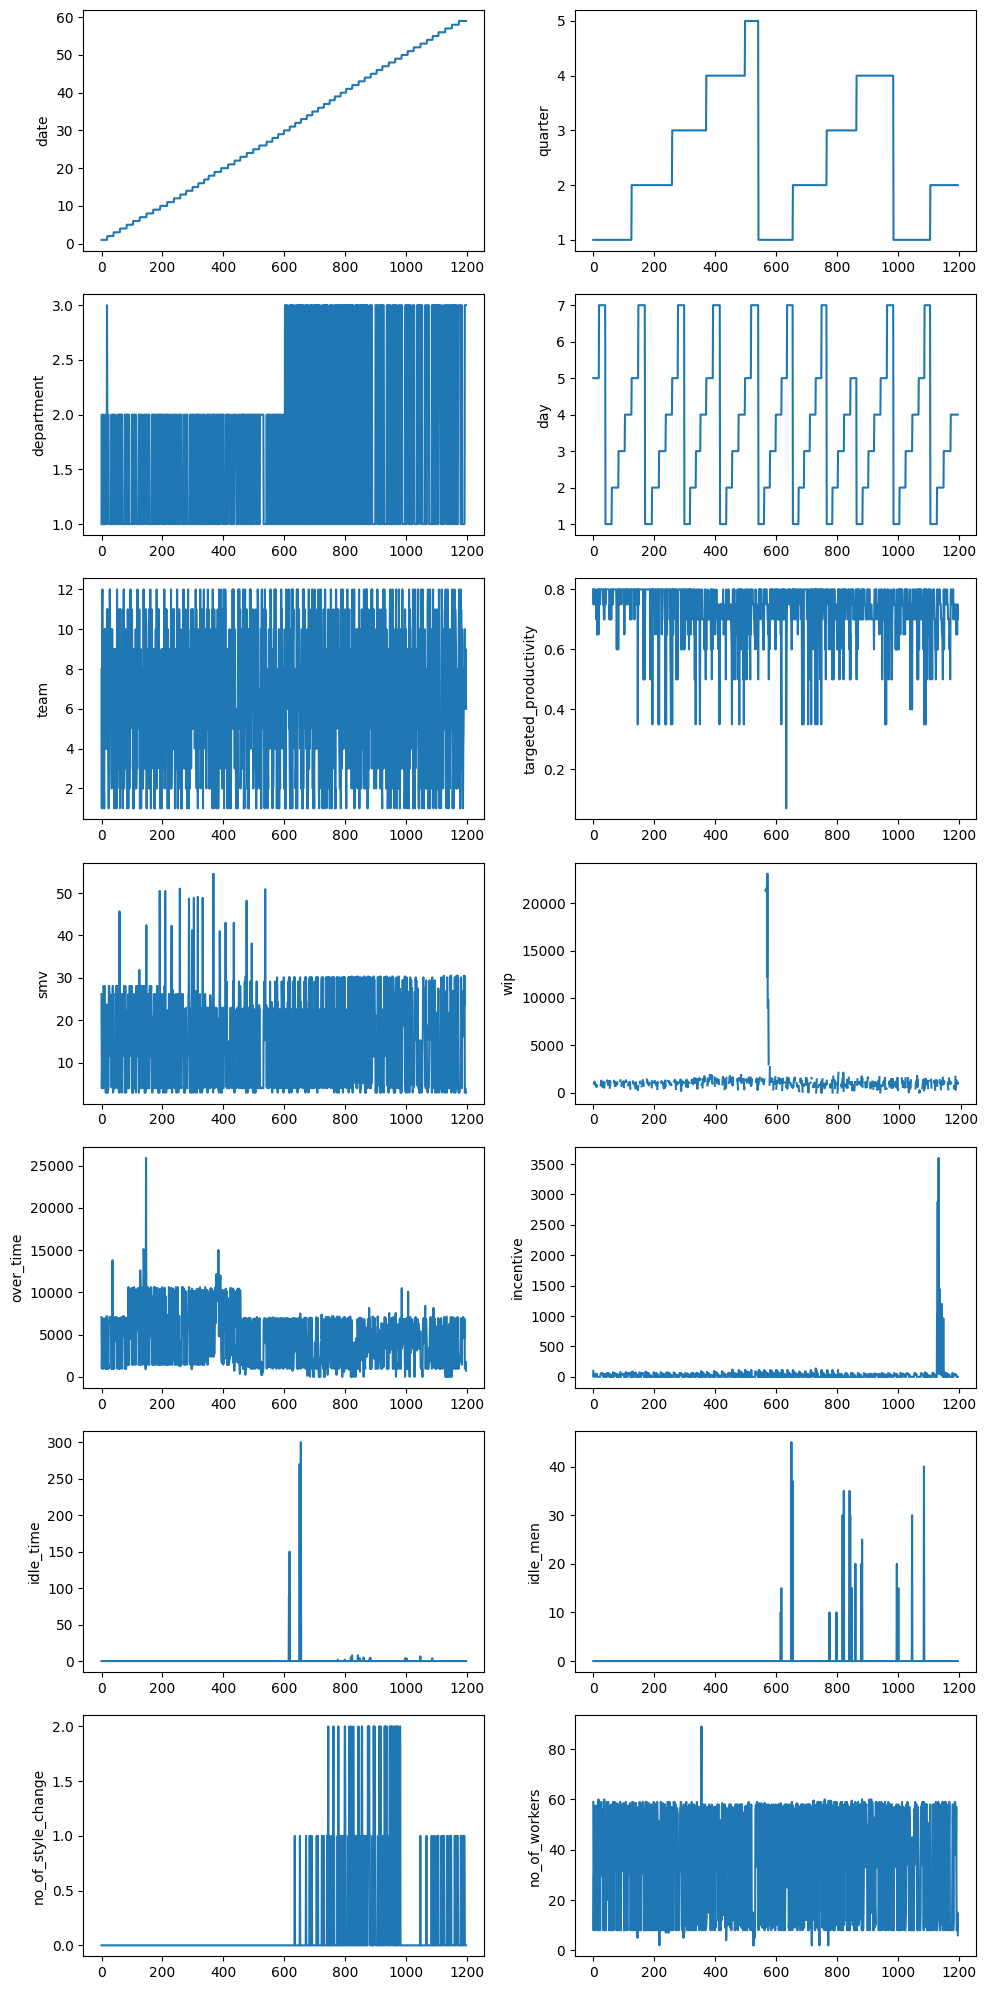

In [43]:
# Try with Pandas plots
fig, axes = plt.subplots(7,2)
fig.set_figheight(20)
fig.set_figwidth(10)
for i, c in enumerate(X.columns.values):
    D.iloc[:, i].plot(y=c, ax=axes[int(i/2), i%2])
    axes[int(i/2), i%2].set_ylabel(c)
fig.tight_layout()

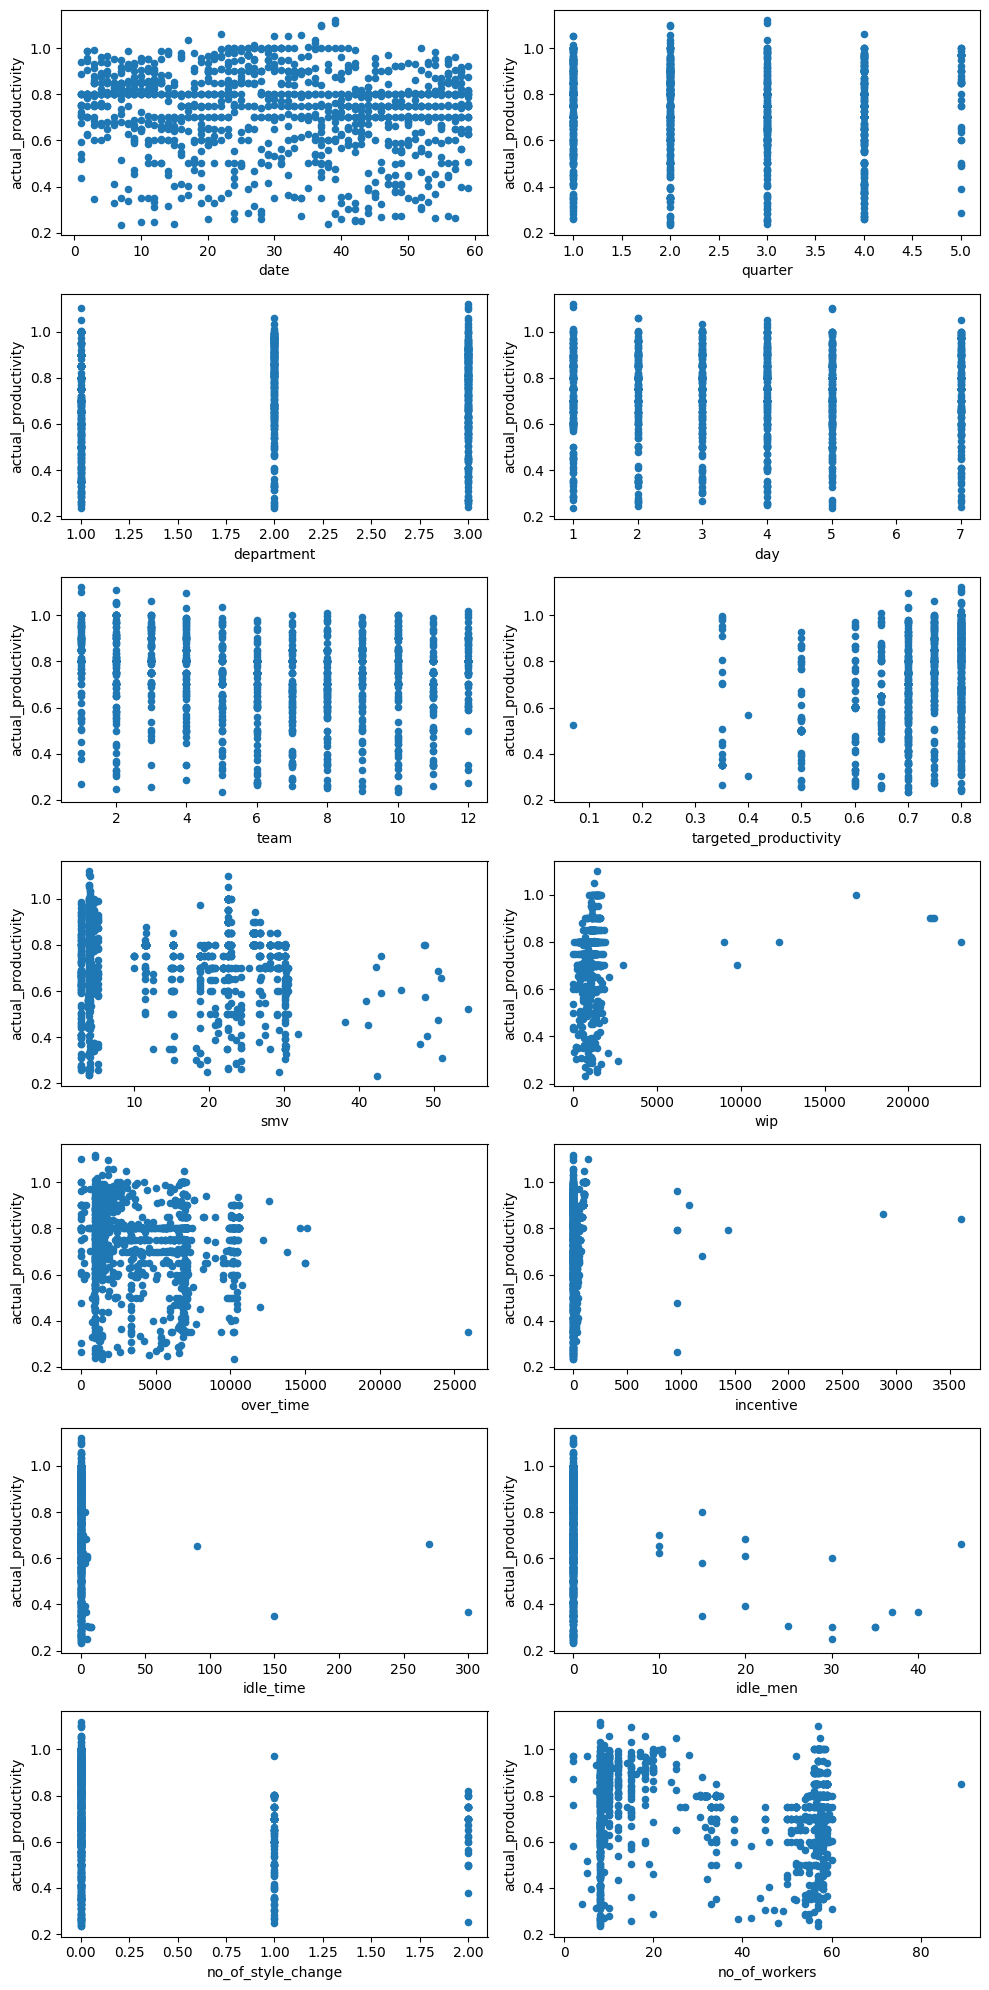

In [44]:
def plot_scatter(D):
    """ Function to quickly create matplotlib subplots"""
    fig, axes = plt.subplots(7,2)
    fig.set_figheight(20)
    fig.set_figwidth(10)
    for i,c  in enumerate(X.columns.values):
        #D.plot.hexbin(c, 'area', ax=axes[int(i/4), i%4])
        D.plot.scatter(c, 'actual_productivity', ax=axes[int(i/2), i%2])
    fig.tight_layout()

plot_scatter(D)

In [45]:
# TODO 7.1
Texp = T.apply(np.exp)

Texp

0       2.561839
1       2.426622
2       2.226811
3       2.226811
4       2.226391
          ...   
1192    1.874484
1193    1.869414
1194    1.869414
1195    1.658459
1196    1.483972
Name: actual_productivity, Length: 1197, dtype: float64

In [46]:
todo_check([
    ("np.all(np.isclose(np.array(Texp)[1193:], np.array([1.86941398, 1.86941398, 1.65845905, 1.48397192])))", "Texp has incorrect values."),
])

Your code PASSED the code check!


In [47]:
pd.concat([T, Texp], axis=1)

,actual_productivity,actual_productivity
0,0.940725,2.561839
1,0.886500,2.426622
2,0.800570,2.226811
3,0.800570,2.226811
4,0.800382,2.226391
...,...,...
1192,0.628333,1.874484
1193,0.625625,1.869414
1194,0.625625,1.869414
1195,0.505889,1.658459


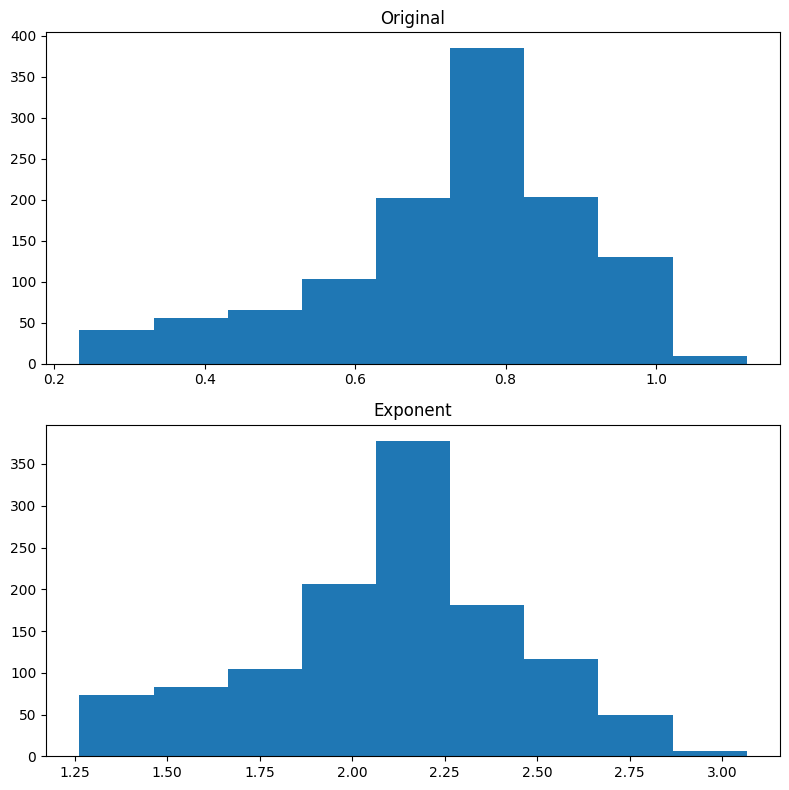

In [48]:
fig = plt.figure(figsize=(8,8))
plt.clf()
plt.subplot(2,1,1)
plt.hist(T, bins=9)
plt.title("Original")
plt.subplot(2,1,2)
plt.hist(Texp, bins=9)
plt.title("Exponent")
fig.tight_layout()

In [49]:
#TODO 8.1
D = pd.concat([X, Texp], axis=1)
D

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1,1,1,5,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,2.561839
1,1,1,2,5,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,2.426622
2,1,1,1,5,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,2.226811
3,1,1,1,5,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,2.226811
4,1,1,1,5,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,2.226391
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59,2,3,4,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,1.874484
1193,59,2,3,4,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,1.869414
1194,59,2,3,4,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,1.869414
1195,59,2,3,4,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,1.658459


In [50]:
todo_check([
    ("D.shape == (1197,15)", "D has the wrong shape."),
    ("np.all(np.isclose(D.loc[:, 'actual_productivity'][1193:], np.array([1.86941398, 1.86941398, 1.65845905, 1.48397192])))", "D column 'area' has incorrect values."),
])

Your code PASSED the code check!


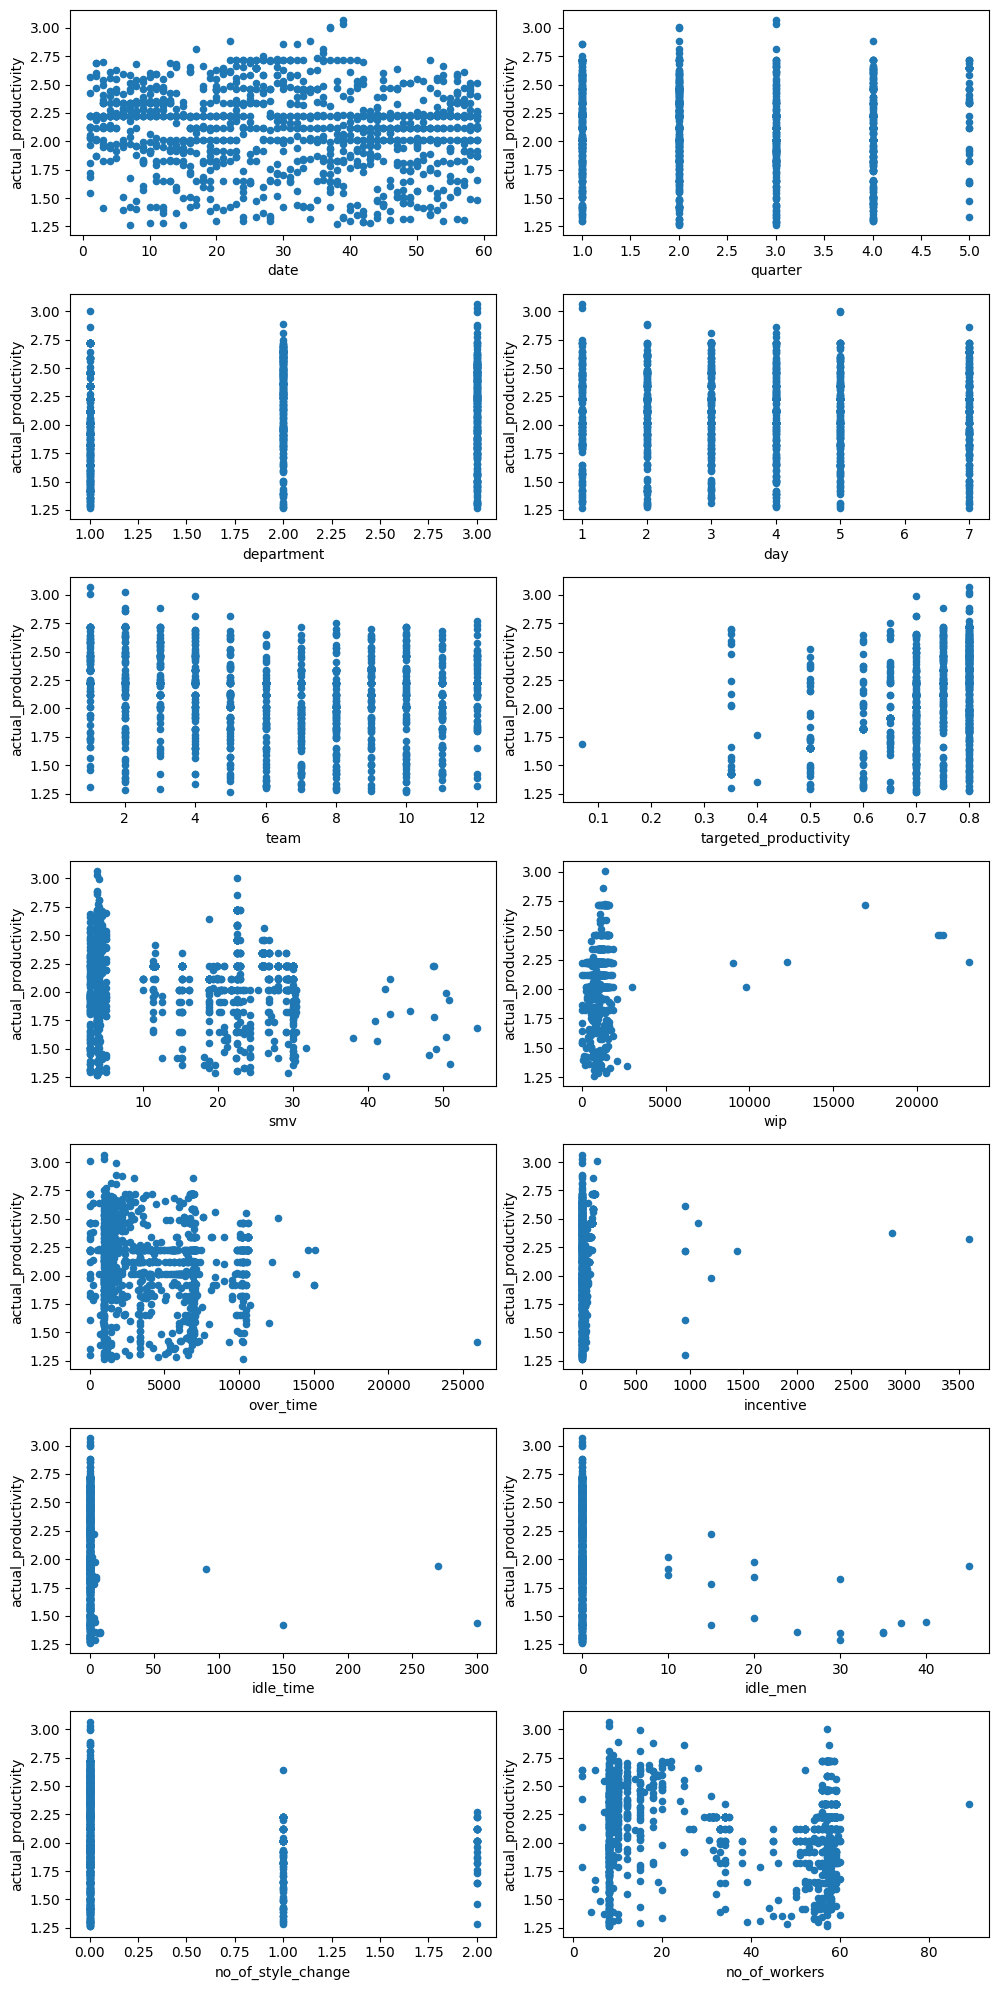

In [51]:
def plot_scatter(D):
    """ Function to quickly create matplotlib subplots"""
    fig, axes = plt.subplots(7,2)
    fig.set_figheight(20)
    fig.set_figwidth(10)
    for i,c  in enumerate(X.columns.values):
        D.plot.scatter(c, 'actual_productivity', ax=axes[int(i/2), i%2])
    fig.tight_layout()

plot_scatter(D)

In [52]:
%%writefile stProductivity.py

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# SETTING PAGE CONFIG TO WIDE MODE
st.set_page_config(layout="wide")

# LOADING DATA
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/597/productivity+prediction+of+garment+employees.zip"
)

"""
# Garment Workers Productivity

Abstract: This dataset includes important attributes of the garment manufacturing process and the productivity of the employees which had been collected manually and also been validated by the industry experts. (https://archive.ics.uci.edu/dataset/597/productivity+prediction+of+garment+employees)).


"""

@st.cache_data
def load_data(nrows):
    data = pd.read_csv(DATA_URL, nrows=nrows)
    return data

data = load_data(100000)


"## Summary"
st.dataframe(data.describe())

Overwriting stProductivity.py


In [53]:
%%writefile -a stProductivity.py


"""
## Raw Data

We can see all the data here by pressing check button.
"""

if st.checkbox("Show Raw Data"):
    data

Appending to stProductivity.py


In [54]:
%%writefile -a stProductivity.py

"## Filtering Data by the Actual Productivity"
#TODO 9.3: add slider to the sidebar
# Determine the min and max values for the slider from the DataFrame
min_value = float(data['actual_productivity'].min())
max_value = float(data['actual_productivity'].max())

# Sidebar with a slider for selecting productivity range
min_prod, max_prod = st.sidebar.slider('Select productivity range', min_value=min_value, max_value=max_value, value=(min_value, max_value))
# Filter data where actual productivity values fall within the selected range
filtered_data = data.query('@min_prod <= actual_productivity <= @max_prod')
st.sidebar.write("actual productivity:", min_prod, "to", max_prod)
st.dataframe(filtered_data)

Appending to stProductivity.py


In [55]:
%%writefile -a stProductivity.py


#TODO 10.1
data = data.query('@min_prod <= actual_productivity <= @max_prod')

"The number of filtered data samples: ", data.shape[0]

Appending to stProductivity.py


In [56]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 23.3.2
[notice] To update, run: C:\Users\indhu\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [57]:
%%writefile -a stProductivity.py
import seaborn as sns  
sns.set(rc={'figure.figsize':(11, 8)})
fig, axes = plt.subplots(2,2,  figsize=(12, 10))

# TODO 10.2


# TODO 10.2: Using plot.hist in pandas, plot histogram of actual_productivity data in axes[0][0] (top-left subplot area)
axes[0][0].hist(filtered_data['actual_productivity'], bins=10, color='skyblue', edgecolor='black')
axes[0][0].set_title('Productivity Histogram')
axes[0][0].set_xlabel('Actual Productivity')
axes[0][0].set_ylabel('Frequency')

# TODO 10.2: Using plot.scatter in pandas, plot actual_productivity vs target_productivity data in axes[0][1] (top-right subplot area)
axes[0][1].scatter(filtered_data['actual_productivity'], filtered_data['targeted_productivity'], alpha=0.5, color='green')
axes[0][1].set_title('Actual vs. Targeted Productivity')
axes[0][1].set_xlabel('Actual Productivity')
axes[0][1].set_ylabel('Targeted Productivity')

# TODO 10.2: Using plot.scatter in pandas, plot actual_productivity vs no_of_workers in axes[1][0] (bottom-left subplot area)
axes[1][0].scatter(filtered_data['actual_productivity'], filtered_data['no_of_workers'], alpha=0.5, color='blue')
axes[1][0].set_title('Actual Productivity vs. Number of Workers')
axes[1][0].set_xlabel('Actual Productivity')
axes[1][0].set_ylabel('Number of Workers')

# TODO 10.2: Using plot.scatter in pandas, plot actual_productivity vs smv in axes[1][1] (bottom-right subplot area)
axes[1][1].scatter(filtered_data['actual_productivity'], filtered_data['smv'], alpha=0.5, color='orange')
axes[1][1].set_title('Actual Productivity vs. SMV')
axes[1][1].set_xlabel('Actual Productivity')
axes[1][1].set_ylabel('SMV')
plt.tight_layout()
st.pyplot(fig)

Appending to stProductivity.py


In [58]:
# This will delete the variables defined in the above section to
# prevent conflicts in future sections.
garbage_collect(['X', 'T', 'D', 'Texp'])

In [59]:
print(f"Original shape: {df.shape}")

# TODO 11.1
# Clean the data by dropping rows with missing values
df_ign = df.dropna()
print(f"New shape {df_ign.shape}")

Original shape: (1197, 15)
New shape (691, 15)


In [60]:
todo_check([
    ("not df_ign.isnull().values.any()", "df_ign still has NaN values"),
    ("df_ign.shape == (691,15)", "df_ign has wrong shape."),
])

Your code PASSED the code check!


In [61]:
i_missing = np.where(df.isna())[0]

In [62]:
df.iloc[i_missing, :]

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
6,1/1/2015,Quarter1,finishing,Thursday,2,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.755167
13,1/1/2015,Quarter1,finishing,Thursday,10,0.65,3.94,NaN,960,0,0.0,0,0,8.0,0.705917
14,1/1/2015,Quarter1,finishing,Thursday,8,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.676667
15,1/1/2015,Quarter1,finishing,Thursday,4,0.75,3.94,NaN,2160,0,0.0,0,0,18.0,0.593056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,3/11/2015,Quarter2,finishing,Wednesday,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,3/11/2015,Quarter2,finishing,Wednesday,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,3/11/2015,Quarter2,finishing,Wednesday,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889


In [63]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 23.3.2
[notice] To update, run: C:\Users\indhu\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [64]:
from sklearn.impute import SimpleImputer

# TODO 12-1.1
imp = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

# Fit the imputer on the data and transform it
df_freq = pd.DataFrame(imp.fit_transform(df), columns=df.columns)
display(df_freq)
np.any(df_freq.isna())

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.8,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,1039.0,960,0,0.0,0,0,8.0,0.8865
2,1/1/2015,Quarter1,sweing,Thursday,11,0.8,11.41,968.0,3660,50,0.0,0,0,30.5,0.80057
3,1/1/2015,Quarter1,sweing,Thursday,12,0.8,11.41,968.0,3660,50,0.0,0,0,30.5,0.80057
4,1/1/2015,Quarter1,sweing,Thursday,6,0.8,25.9,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday,10,0.75,2.9,1039.0,960,0,0.0,0,0,8.0,0.628333
1193,3/11/2015,Quarter2,finishing,Wednesday,8,0.7,3.9,1039.0,960,0,0.0,0,0,8.0,0.625625
1194,3/11/2015,Quarter2,finishing,Wednesday,7,0.65,3.9,1039.0,960,0,0.0,0,0,8.0,0.625625
1195,3/11/2015,Quarter2,finishing,Wednesday,9,0.75,2.9,1039.0,1800,0,0.0,0,0,15.0,0.505889


False

In [65]:
todo_check([
    ("not np.any(df_freq.isna())", "df_freq still has NaN values"),
    ("df_freq.iloc[13, 0] == '1/1/2015'", "df_freq has incorrect values.")
])

Your code PASSED the code check!


In [66]:
df_freq.iloc[i_missing, :]

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,1039.0,960,0,0.0,0,0,8.0,0.8865
6,1/1/2015,Quarter1,finishing,Thursday,2,0.75,3.94,1039.0,960,0,0.0,0,0,8.0,0.755167
13,1/1/2015,Quarter1,finishing,Thursday,10,0.65,3.94,1039.0,960,0,0.0,0,0,8.0,0.705917
14,1/1/2015,Quarter1,finishing,Thursday,8,0.75,2.9,1039.0,960,0,0.0,0,0,8.0,0.676667
15,1/1/2015,Quarter1,finishing,Thursday,4,0.75,3.94,1039.0,2160,0,0.0,0,0,18.0,0.593056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday,10,0.75,2.9,1039.0,960,0,0.0,0,0,8.0,0.628333
1193,3/11/2015,Quarter2,finishing,Wednesday,8,0.7,3.9,1039.0,960,0,0.0,0,0,8.0,0.625625
1194,3/11/2015,Quarter2,finishing,Wednesday,7,0.65,3.9,1039.0,960,0,0.0,0,0,8.0,0.625625
1195,3/11/2015,Quarter2,finishing,Wednesday,9,0.75,2.9,1039.0,1800,0,0.0,0,0,15.0,0.505889


In [67]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
try:
    # TODO 12-2.1
     df_mean = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

except ValueError as e:
    exc = e
    traceback.print_exc()

Traceback (most recent call last):
  File "C:\Users\indhu\AppData\Local\Temp\ipykernel_27948\2737461364.py", line 6, in <module>
    df_mean = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
                           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_set_output.py", line 273, in wrapped
    data_to_wrap = f(self, X, *args, **kwargs)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1061, in fit_transform
    return self.fit(X, **fit_params).transform(X)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1351, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\indhu\AppData\Local\Programs\Python\Python312\Lib\site-packages\s

In [68]:
todo_check([
    ("isinstance(exc, ValueError)", "exc should be a ValueError!"),
    ("str(exc).startswith('Cannot use mean strategy with non-numeric data')", "exc contains the wrong ValueError")
])

Your code PASSED the code check!


In [69]:
df["date"].unique().shape

(59,)

In [70]:
quarterdic = {'Quarter1': 1, 'Quarter2':2, 'Quarter3':3, 'Quarter4':4, 'Quarter5':5}
daydic = {'Sunday': 1, 'Monday':2, 'Tuesday':3, 'Wednesday':4, 'Thursday':5, 'Friday':6, 'Saturday':7 }
departmentdic = {'sweing': 1, 'finishing ':2, 'finishing':3}
dates_list = df["date"].unique()
datedic = {dates_list[i]:i+1 for i in range(len(dates_list))}

new_df = df.copy()
new_df['date'] = new_df['date'].apply(lambda x: datedic[x])
new_df['quarter'] = new_df['quarter'].apply(lambda x: quarterdic[x])
new_df['department'] = new_df['department'].apply(lambda x: departmentdic[x])
new_df['day'] = new_df['day'].apply(lambda x: daydic[x])
new_df

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1,1,1,5,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1,1,2,5,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1,1,1,5,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1,1,1,5,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1,1,1,5,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59,2,3,4,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,59,2,3,4,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,59,2,3,4,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,59,2,3,4,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889


In [71]:
from sklearn.impute import SimpleImputer
# TODO 12-3.1

df_mean = pd.DataFrame(imputer.fit_transform(new_df), columns=new_df.columns)

display(df_mean)
np.any(df_mean.isna())

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1.0,1.0,1.0,5.0,8.0,0.80,26.16,1108.000000,7080.0,98.0,0.0,0.0,0.0,59.0,0.940725
1,1.0,1.0,2.0,5.0,1.0,0.75,3.94,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.886500
2,1.0,1.0,1.0,5.0,11.0,0.80,11.41,968.000000,3660.0,50.0,0.0,0.0,0.0,30.5,0.800570
3,1.0,1.0,1.0,5.0,12.0,0.80,11.41,968.000000,3660.0,50.0,0.0,0.0,0.0,30.5,0.800570
4,1.0,1.0,1.0,5.0,6.0,0.80,25.90,1170.000000,1920.0,50.0,0.0,0.0,0.0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59.0,2.0,3.0,4.0,10.0,0.75,2.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.628333
1193,59.0,2.0,3.0,4.0,8.0,0.70,3.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1194,59.0,2.0,3.0,4.0,7.0,0.65,3.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1195,59.0,2.0,3.0,4.0,9.0,0.75,2.90,1190.465991,1800.0,0.0,0.0,0.0,0.0,15.0,0.505889


False

In [72]:
todo_check([
    ("not np.any(df_mean.isna())", "df_mean still has NaN values"),
    ("np.isclose(df_mean.iloc[2, 7], 968.0)", "df_mean has incorrect values.")
])

Your code PASSED the code check!


In [73]:
df_mean.iloc[i_missing, :]

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1,1.0,1.0,2.0,5.0,1.0,0.75,3.94,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.886500
6,1.0,1.0,2.0,5.0,2.0,0.75,3.94,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.755167
13,1.0,1.0,2.0,5.0,10.0,0.65,3.94,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.705917
14,1.0,1.0,2.0,5.0,8.0,0.75,2.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.676667
15,1.0,1.0,2.0,5.0,4.0,0.75,3.94,1190.465991,2160.0,0.0,0.0,0.0,0.0,18.0,0.593056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59.0,2.0,3.0,4.0,10.0,0.75,2.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.628333
1193,59.0,2.0,3.0,4.0,8.0,0.70,3.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1194,59.0,2.0,3.0,4.0,7.0,0.65,3.90,1190.465991,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1195,59.0,2.0,3.0,4.0,9.0,0.75,2.90,1190.465991,1800.0,0.0,0.0,0.0,0.0,15.0,0.505889


In [74]:
from sklearn.impute import KNNImputer

# TODO 12-4.1
imp_knn = KNNImputer(n_neighbors=5, weights="uniform")
df_knn = pd.DataFrame(imp_knn.fit_transform(new_df), columns=new_df.columns)
display(df_knn)
np.any(df_knn.isna())

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1.0,1.0,1.0,5.0,8.0,0.80,26.16,1108.0,7080.0,98.0,0.0,0.0,0.0,59.0,0.940725
1,1.0,1.0,2.0,5.0,1.0,0.75,3.94,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.886500
2,1.0,1.0,1.0,5.0,11.0,0.80,11.41,968.0,3660.0,50.0,0.0,0.0,0.0,30.5,0.800570
3,1.0,1.0,1.0,5.0,12.0,0.80,11.41,968.0,3660.0,50.0,0.0,0.0,0.0,30.5,0.800570
4,1.0,1.0,1.0,5.0,6.0,0.80,25.90,1170.0,1920.0,50.0,0.0,0.0,0.0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59.0,2.0,3.0,4.0,10.0,0.75,2.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.628333
1193,59.0,2.0,3.0,4.0,8.0,0.70,3.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1194,59.0,2.0,3.0,4.0,7.0,0.65,3.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1195,59.0,2.0,3.0,4.0,9.0,0.75,2.90,632.8,1800.0,0.0,0.0,0.0,0.0,15.0,0.505889


False

In [75]:
todo_check([
    ("not np.any(df_knn.isna())", "df_knn still has NaN values"),
    ("np.isclose(df_knn.iloc[1192, 7], 994.4)", "df_knn has incorrect values.")
])

Your code PASSED the code check!


In [76]:
df_knn.iloc[i_missing, :]

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1,1.0,1.0,2.0,5.0,1.0,0.75,3.94,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.886500
6,1.0,1.0,2.0,5.0,2.0,0.75,3.94,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.755167
13,1.0,1.0,2.0,5.0,10.0,0.65,3.94,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.705917
14,1.0,1.0,2.0,5.0,8.0,0.75,2.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.676667
15,1.0,1.0,2.0,5.0,4.0,0.75,3.94,919.6,2160.0,0.0,0.0,0.0,0.0,18.0,0.593056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,59.0,2.0,3.0,4.0,10.0,0.75,2.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.628333
1193,59.0,2.0,3.0,4.0,8.0,0.70,3.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1194,59.0,2.0,3.0,4.0,7.0,0.65,3.90,994.4,960.0,0.0,0.0,0.0,0.0,8.0,0.625625
1195,59.0,2.0,3.0,4.0,9.0,0.75,2.90,632.8,1800.0,0.0,0.0,0.0,0.0,15.0,0.505889


In [77]:
from sklearn.utils import resample
# TODO 13.1
# Set the random seed for reproducibility
random_seed = 42
df_sample = resample(new_df, n_samples=100, random_state=random_seed)
display(df_sample)
df_sample.shape

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
1126,56,2,3,1,10,0.70,2.90,NaN,960,0,0.0,0,0,8.0,0.441042
860,43,3,1,5,7,0.75,30.10,444.0,0,0,5.0,20,1,59.0,0.611141
1130,57,2,3,2,5,0.60,3.94,NaN,0,2880,0.0,0,0,12.0,0.864343
1095,55,1,3,7,6,0.50,2.90,NaN,960,0,0.0,0,0,8.0,0.797500
1044,52,1,3,3,5,0.70,4.60,NaN,3360,0,0.0,0,0,8.0,0.354444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017,51,1,1,2,9,0.75,18.79,935.0,6240,45,0.0,0,0,52.0,0.750396
40,3,1,2,1,3,0.75,4.15,NaN,1560,0,0.0,0,0,8.0,0.991389
1051,53,1,3,4,1,0.70,3.94,NaN,960,0,0.0,0,0,8.0,0.806879
134,7,2,2,5,2,0.80,3.94,NaN,1440,0,0.0,0,0,8.0,0.835758


(100, 15)

In [78]:
todo_check([
    ("df_sample.shape == (100,15)", "df_sample has the wrong shape")
])

Your code PASSED the code check!


<Axes: ylabel='Frequency'>

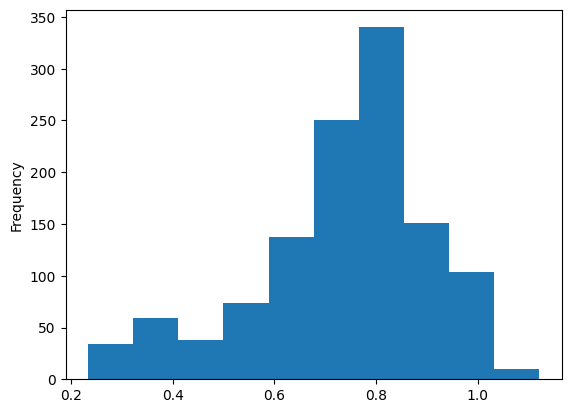

In [79]:
new_df['actual_productivity'].plot.hist()

<Axes: ylabel='Frequency'>

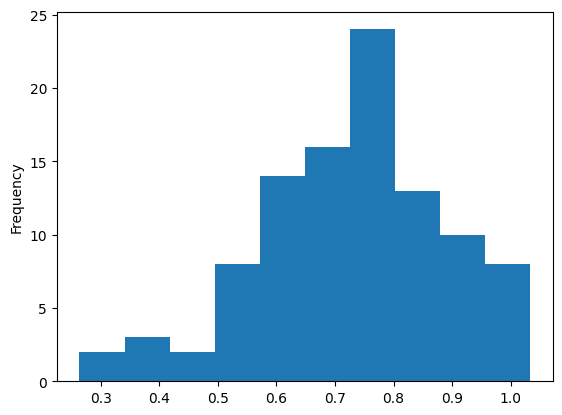

In [80]:
df_sample['actual_productivity'].plot.hist()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
894,45,4,1,2,2,0.70,30.33,577.0,2160,30,0.0,0,1,58.0,0.700623
163,8,2,1,7,10,0.80,28.08,1082.0,10530,63,0.0,0,0,58.5,0.800000
421,21,4,2,1,4,0.75,4.30,NaN,2160,0,0.0,0,0,12.0,0.952020
461,23,4,1,3,10,0.80,22.52,1134.0,6720,70,0.0,0,0,56.0,0.900130
1080,54,1,1,5,4,0.70,26.82,1117.0,7080,50,0.0,0,0,59.0,0.750051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
646,32,1,3,7,9,0.80,3.94,NaN,960,0,0.0,0,0,8.0,0.771583
323,16,3,1,2,9,0.80,26.16,1196.0,10620,63,0.0,0,0,59.0,0.800117
748,37,2,1,5,3,0.35,30.10,770.0,6960,0,0.0,0,1,58.0,0.350302
381,19,4,1,5,11,0.70,14.89,1863.0,10260,50,0.0,0,0,57.0,0.700170


(100, 15)

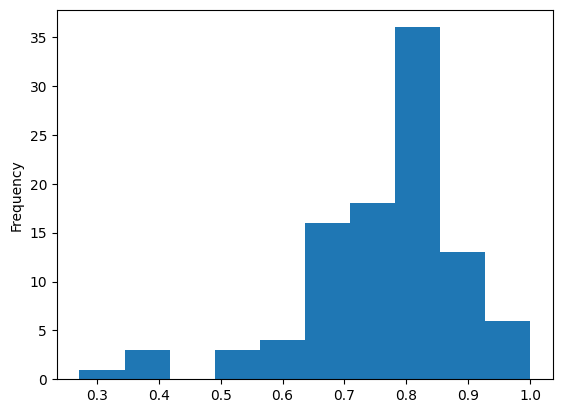

In [81]:
# TODO 14.1
random_seed = 42
stratify_column ='actual_productivity'
df_strat = resample(new_df, n_samples=100, random_state=random_seed, stratify=new_df[stratify_column])
display(df_strat)
df_strat['actual_productivity'].plot.hist()
df_strat.shape

In [82]:
todo_check([
    ("df_strat.shape == (100,15)", "df_strat has the wrong shape")
])

Your code PASSED the code check!


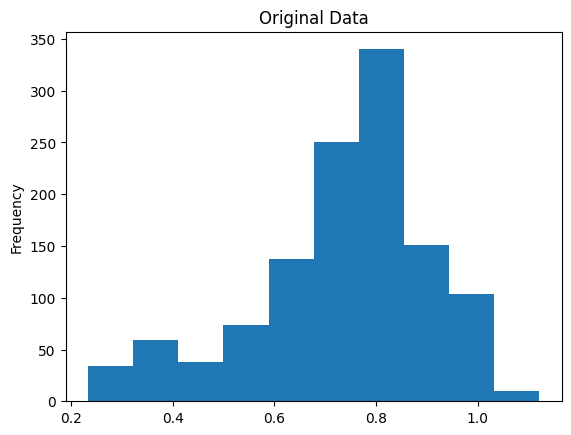

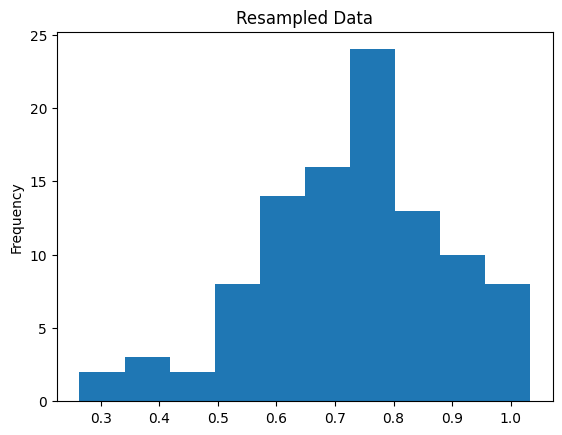

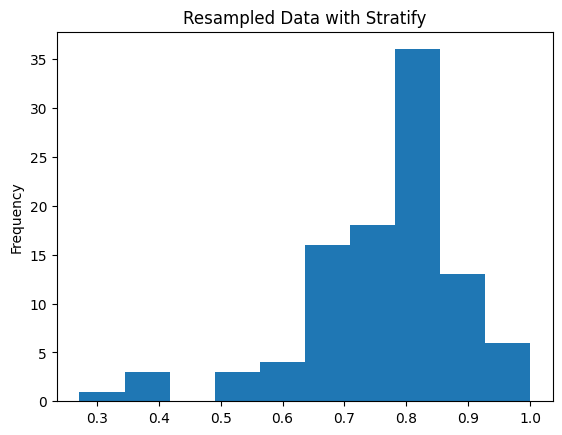

In [83]:
new_df['actual_productivity'].plot.hist()
plt.title("Original Data")
plt.show()
df_sample['actual_productivity'].plot.hist()
plt.title("Resampled Data")
plt.show()
df_strat['actual_productivity'].plot.hist()
plt.title("Resampled Data with Stratify")
plt.show()

In [84]:
from sklearn.decomposition import PCA

print(df_knn.shape)

pca = PCA(n_components=5)

df_pca = pd.DataFrame(pca.fit_transform(df_knn))

# Note, alternatively we could do the following...
# pca.fit(df)
# df_pca = pd.DataFrame(pca.transform(df))

display(df_pca)

# percentage of variance explained by each of the selected components.
pca.explained_variance_ratio_

(1197, 15)


,0,1,2,3,4
0,2511.870523,-73.714669,60.513494,9.761059,-27.249945
1,-3607.275807,85.739911,-39.853140,30.174636,-16.702644
2,-911.079880,-61.004937,11.665635,21.956280,-20.718667
3,-911.079981,-61.004989,11.665485,21.960015,-20.718946
4,-2640.127751,218.582653,9.849174,-3.244087,-49.174146
...,...,...,...,...,...
1192,-3607.355877,85.747398,-39.198549,-10.794218,24.174566
1193,-3607.353472,85.747485,-39.195784,-11.106099,23.873499
1194,-3607.353371,85.747537,-39.195635,-11.109862,23.873804
1195,-2784.338376,-313.030791,-36.502175,-13.000649,23.550798


array([8.48236108e-01, 1.49774786e-01, 1.93190839e-03, 2.64428813e-05,
       1.53689666e-05])

In [85]:
from sklearn.preprocessing import Normalizer

# TODO 15-1.1
normalizer = Normalizer(norm='max')
# Fit and transform the normalizer on the data
df_scalemax = pd.DataFrame(normalizer.fit_transform(df_knn))
df_scalemax.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
count,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,0.013855,0.001031,0.000874,0.001541,0.002914,0.000318,0.004177,0.387579,0.957917,0.012634,0.000167,0.000353,0.000050,0.010023,0.000319
std,0.019308,0.001268,0.000985,0.001767,0.004537,0.000349,0.007274,0.315254,0.180172,0.075662,0.002136,0.005599,0.000359,0.021122,0.000355
min,0.000139,0.000043,0.000039,0.000086,0.000059,0.000010,0.000263,0.000989,0.000000,0.000000,0.000000,0.000000,0.000000,0.001389,0.000014
25%,0.003047,0.000287,0.000145,0.000439,0.000694,0.000105,0.002306,0.141762,1.000000,0.000000,0.000000,0.000000,0.000000,0.005556,0.000101
50%,0.007532,0.000601,0.000275,0.000877,0.001488,0.000189,0.003264,0.236601,1.000000,0.000000,0.000000,0.000000,0.000000,0.008262,0.000179
75%,0.016667,0.001389,0.001389,0.002011,0.003750,0.000556,0.004070,0.575833,1.000000,0.007212,0.000000,0.000000,0.000000,0.008333,0.000501
max,0.330097,0.019417,0.009709,0.019417,0.106796,0.007282,0.164246,1.000000,1.000000,1.000000,0.043860,0.167598,0.011173,0.524272,0.007288


In [86]:
todo_check([
    ("np.all(np.isclose(df_scalemax.describe().loc['mean', [0,3,5]].values, np.array([0.01385537, 0.00154133, 0.00031804])))",
     "df_scalemax has incorrect values")
])

Your code PASSED the code check!


In [87]:
from sklearn.preprocessing import StandardScaler

# TODO 15-2.1
scaler = StandardScaler()
df_zscale = pd.DataFrame(scaler.fit_transform(df_knn))

df_zscale.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
count,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1197.000000,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03,1.197000e+03
mean,9.497647e-17,7.123235e-17,1.187206e-16,8.904044e-18,7.197436e-17,-3.531938e-16,9.942849e-17,9.497647e-17,1.187206e-16,0.000000,5.936030e-18,2.374412e-17,-4.748824e-17,-3.784219e-17,-2.374412e-17
std,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00,1.000418e+00
min,-1.667410e+00,-1.151688e+00,-7.829760e-01,-1.348495e+00,-1.567329e+00,-6.741257e+00,-1.111853e+00,-7.514268e-01,-1.364470e+00,-0.238643,-5.747269e-02,-1.130047e-01,-3.516175e-01,-1.469680e+00,-2.874670e+00
25%,-8.597546e-01,-1.151688e+00,-7.829760e-01,-8.349257e-01,-9.897140e-01,-3.028349e-01,-1.016778e+00,-2.011900e-01,-9.342886e-01,-0.238643,-5.747269e-02,-1.130047e-01,-3.516175e-01,-1.154200e+00,-4.861047e-01
50%,-5.209903e-02,-3.286608e-01,-7.829760e-01,-3.213563e-01,-1.232920e-01,2.081510e-01,1.808523e-02,-7.052465e-02,-1.814710e-01,-0.238643,-5.747269e-02,-1.130047e-01,-3.516175e-01,-2.748543e-02,2.192600e-01
75%,8.709359e-01,4.943663e-01,4.583780e-01,7.057825e-01,7.431300e-01,7.191368e-01,8.408561e-01,3.270662e-02,7.147405e-01,0.073631,-5.747269e-02,-1.130047e-01,-3.516175e-01,1.009092e+00,6.602725e-01
max,1.678591e+00,2.140420e+00,1.699732e+00,1.732921e+00,1.609552e+00,7.191368e-01,3.610851e+00,1.559235e+01,6.378797e+00,22.245096,2.355631e+01,1.365848e+01,4.324895e+00,2.451286e+00,2.209365e+00


In [88]:
todo_check([
    ("np.all(np.isclose(df_zscale.describe().loc['mean', [0,3,5]].values, np.array([1.29590945e-15, 1.08147038e-16, 1.90741324e-16])))",
     "df_zscale has incorrect values")
])

Your code PASSED the code check!


In [89]:
X = 'team'
Y = 'no_of_workers'
new_df.loc[:, [X,Y, 'actual_productivity']]

,team,no_of_workers,actual_productivity
0,8,59.0,0.940725
1,1,8.0,0.886500
2,11,30.5,0.800570
3,12,30.5,0.800570
4,6,56.0,0.800382
...,...,...,...
1192,10,8.0,0.628333
1193,8,8.0,0.625625
1194,7,8.0,0.625625
1195,9,15.0,0.505889


In [90]:
new_df.loc[:, [X,Y]].max(axis=0)

team             12.0
no_of_workers    89.0
dtype: float64

In [91]:
new_df.loc[:, [X,Y]].min(axis=0)

team             1.0
no_of_workers    2.0
dtype: float64

In [92]:
x_domain, y_doamin = np.arange(start=0, stop=14), np.arange(start=0, stop=91)
print("Domain for the x-axis: {}".format(x_domain))
print("Domain for the y-axis: {}".format(y_doamin))

Domain for the x-axis: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]
Domain for the y-axis: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90]


In [93]:
xs, ys = np.meshgrid(x_domain, y_doamin)

print(xs)
print(ys)

[[ 0  1  2 ... 11 12 13]
 [ 0  1  2 ... 11 12 13]
 [ 0  1  2 ... 11 12 13]
 ...
 [ 0  1  2 ... 11 12 13]
 [ 0  1  2 ... 11 12 13]
 [ 0  1  2 ... 11 12 13]]
[[ 0  0  0 ...  0  0  0]
 [ 1  1  1 ...  1  1  1]
 [ 2  2  2 ...  2  2  2]
 ...
 [88 88 88 ... 88 88 88]
 [89 89 89 ... 89 89 89]
 [90 90 90 ... 90 90 90]]


In [94]:
act = new_df.loc[new_df.loc[:, 'actual_productivity'] > 0, [X,Y, 'actual_productivity']]
act

,team,no_of_workers,actual_productivity
0,8,59.0,0.940725
1,1,8.0,0.886500
2,11,30.5,0.800570
3,12,30.5,0.800570
4,6,56.0,0.800382
...,...,...,...
1192,10,8.0,0.628333
1193,8,8.0,0.625625
1194,7,8.0,0.625625
1195,9,15.0,0.505889


In [95]:
zs = np.zeros(xs.shape)
zs

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [96]:
fig = plt.figure()
zs = np.zeros(xs.shape)
i = 0
for _, sample in new_df.iterrows():
    i+= 1
    x, y = int(sample[X]), int(sample[Y])
    zs[y, x] += sample['actual_productivity']

<Figure size 640x480 with 0 Axes>

In [97]:
pd.DataFrame(zs)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
1,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
2,0.0,0.95142,0.0,0.0,0.0,3.1827,0.000000,0.0,0.000000,0.971867,0.0,0.0,0.0,0.0
3,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
4,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.329545,0.000000,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
87,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
88,0.0,0.00000,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
89,0.0,0.00000,0.0,0.0,0.0,0.0000,0.850411,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0


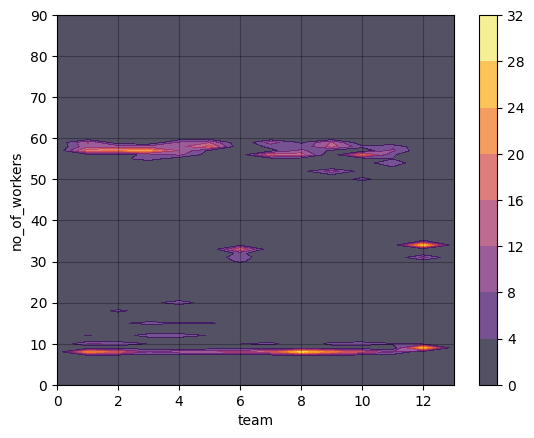

In [98]:
plt.contourf(xs, ys, zs, alpha=0.7, cmap=plt.cm.inferno,)
plt.colorbar()
plt.xlabel(X)
plt.ylabel(Y)
plt.grid(c='k', ls='-', alpha=0.3)

In [99]:
# TODO 16.1
exp_prod = np.exp(new_df['actual_productivity'])
exp_prod

0       2.561839
1       2.426622
2       2.226811
3       2.226811
4       2.226391
          ...   
1192    1.874484
1193    1.869414
1194    1.869414
1195    1.658459
1196    1.483972
Name: actual_productivity, Length: 1197, dtype: float64

In [100]:
todo_check([
    ("np.all(np.isclose(np.array(exp_prod)[1192:], np.array([1.87448383, 1.86941398, 1.86941398, 1.65845905, 1.48397192]))),",
     "exp_prod has incorrect values.")
])

Your code PASSED the code check!


In [101]:
new_df.loc[:,'quarter']

0       1
1       1
2       1
3       1
4       1
       ..
1192    2
1193    2
1194    2
1195    2
1196    2
Name: quarter, Length: 1197, dtype: int64

In [102]:
# TODO 17-1.1
indicator_quarter = pd.get_dummies(new_df['quarter'])
indicator_quarter

,1,2,3,4,5
0,True,False,False,False,False
1,True,False,False,False,False
2,True,False,False,False,False
3,True,False,False,False,False
4,True,False,False,False,False
...,...,...,...,...,...
1192,False,True,False,False,False
1193,False,True,False,False,False
1194,False,True,False,False,False
1195,False,True,False,False,False


In [103]:
todo_check([
    ("indicator_quarter.shape == (1197,5)", "indicator_quarter has wrong shape."),
     ("np.all(indicator_quarter.iloc[1].values == np.array([1,0,0,0,0], dtype=np.uint8))", "indicator_quarter has incorrect values.")
])

Your code PASSED the code check!


In [104]:
# TODO 17-1.2
indicator_day = pd.get_dummies(new_df['day'])
indicator_day

,1,2,3,4,5,7
0,False,False,False,False,True,False
1,False,False,False,False,True,False
2,False,False,False,False,True,False
3,False,False,False,False,True,False
4,False,False,False,False,True,False
...,...,...,...,...,...,...
1192,False,False,False,True,False,False
1193,False,False,False,True,False,False
1194,False,False,False,True,False,False
1195,False,False,False,True,False,False


In [105]:
todo_check([
    ("indicator_day.shape == (1197,6)", "indicator_day has wrong shape."),
    ("np.all(indicator_day.iloc[-1].values == np.array([0, 0, 0, 1, 0, 0], dtype=np.uint8))", "indicator_day has incorrect values.")
])

Your code PASSED the code check!


In [106]:
# This will delete the variables defined in the above section to
# prevent conflicts in future sections.
garbage_collect(['indicator_day', 'indicator_quarter'])

In [107]:
df[['date','quarter','department', 'day']]

,date,quarter,department,day
0,1/1/2015,Quarter1,sweing,Thursday
1,1/1/2015,Quarter1,finishing,Thursday
2,1/1/2015,Quarter1,sweing,Thursday
3,1/1/2015,Quarter1,sweing,Thursday
4,1/1/2015,Quarter1,sweing,Thursday
...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday
1193,3/11/2015,Quarter2,finishing,Wednesday
1194,3/11/2015,Quarter2,finishing,Wednesday
1195,3/11/2015,Quarter2,finishing,Wednesday


In [108]:
from sklearn.preprocessing import OneHotEncoder

# TODO 17-2.1
unique_dates = df['date'].unique()
unique_quarters = df['quarter'].unique()
unique_depts = df['department'].unique()
unique_days = df['day'].unique()

# TODO 17-2.2
encoder = OneHotEncoder(categories=[unique_dates, unique_quarters, unique_depts, unique_days])
# TODO 17-2.3
one_hot_encoded = encoder.fit_transform(df[['date', 'quarter', 'department', 'day']])
indicator_md = pd.DataFrame(one_hot_encoded.toarray())
df

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,3/11/2015,Quarter2,finishing,Wednesday,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,3/11/2015,Quarter2,finishing,Wednesday,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,3/11/2015,Quarter2,finishing,Wednesday,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,3/11/2015,Quarter2,finishing,Wednesday,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889


In [109]:
todo_check([
    ("isinstance(indicator_md, pd.DataFrame)", "indicator_md is not of type pd.DataFrame"),
    ("indicator_md.shape == (1197, 73)", "indicator_md has the wrong shape.")
])

Your code PASSED the code check!


In [110]:
display(df.iloc[:, 4:])

,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...
1192,10,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,8,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,7,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,9,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889


In [111]:
pd.concat([indicator_md, df.iloc[:, 4:]], axis=1)

,0,1,2,3,4,5,6,7,8,9,...,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1192,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.75,2.90,NaN,960,0,0.0,0,0,8.0,0.628333
1193,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.70,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1194,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.65,3.90,NaN,960,0,0.0,0,0,8.0,0.625625
1195,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.75,2.90,NaN,1800,0,0.0,0,0,15.0,0.505889
